# Phase 4 — Classical Avellaneda–Stoikov Market Making
### Hawkes-Process-Driven Market Making · LOBSTER AAPL 2012-06-21

Phases 1–3 established that AAPL trade arrivals **cluster** and are **not Poisson**, and produced a
validated Hawkes estimate ($\rho\approx0.47$). This phase deliberately *sets that aside* and builds
the **original Avellaneda–Stoikov (2008) model** faithfully — a constant-volatility, **Poisson**-
arrival, closed-form market-making baseline. It is the control against which the Hawkes extension
(next phase) will be measured.

**What AS gives us.** A principled answer to two coupled questions a market maker faces every instant:

1. *Where is the centre of my quotes?* → the **reservation price** $r(t,q)$, which leans against
   inventory.
2. *How wide should I quote?* → the **optimal spread** $\delta^*(t)$, balancing the profit per fill
   against inventory risk and the elasticity of order flow.

This notebook derives both from the model's assumptions, calibrates the two empirical inputs
($\sigma,\kappa$) from LOBSTER, runs the event-driven simulator, and verifies the model's
qualitative predictions numerically. It *uses the deliverable modules* in `market_maker/`.

---
## 0. Setup

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display

from market_maker import ASParameters
from market_maker.avellaneda_stoikov import (reservation_price, optimal_spread,
                                             compute_quotes, calibrate_sigma, calibrate_kappa)
from market_maker.execution_model import ExecutionModel
from market_maker.simulator import simulate_episode, plot_episode

sns.set_theme(context="notebook", style="whitegrid")
PLOTS = "../plots/avellaneda_stoikov"; RESULTS = "../results"
DATA = "../LOBSTER_SampleFile_AAPL_2012-06-21_10/AAPL_2012-06-21_34200000_57600000_"
plt.rcParams["figure.dpi"] = 110

## 1. Mid-price dynamics and calibrating $\sigma$

**Assumption (eq. 1).** The mid-price is a *driftless arithmetic Brownian motion*

$$dS_t = \sigma\, dW_t.$$

Three things are being assumed: **(a) no drift** — the maker takes no directional view, only earns
the spread; **(b) constant volatility** $\sigma$; **(c) additive (not multiplicative) noise** — over
a short horizon and a small price range, arithmetic BM is a fine local approximation and keeps the
control problem linear.

Under this model, mid-price increments over a fixed interval $\Delta t$ are i.i.d.
$\mathcal N(0,\sigma^2\Delta t)$, so $\hat\sigma=\mathrm{std}(\Delta S)/\sqrt{\Delta t}$.

In [2]:
cols = ["time","etype","oid","size","price","dir"]
msg = pd.read_csv(DATA+"message_10.csv", header=None, names=cols)
obn = sum([[f"ap{i}",f"as{i}",f"bp{i}",f"bs{i}"] for i in range(1,11)], [])
ob = pd.read_csv(DATA+"orderbook_10.csv", header=None, names=obn)
mid = ((ob.ap1+ob.bp1)/2/10000.0).to_numpy(); t = msg.time.to_numpy()

sigma = calibrate_sigma(t, mid, sample_dt=1.0)
print(f"sigma_hat = {sigma:.5f} $/sqrt(s)   (=> daily move ~ ${sigma*np.sqrt(23400):.2f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot((t-t[0])/3600, mid, lw=0.4, color="black"); ax[0].set(xlabel="hours", ylabel="mid ($)",
        title=f"AAPL mid-price (sigma={sigma:.4f} $/sqrt(s))")
tu, iu = np.unique(t, return_index=True); mu = mid[iu]   # de-duplicate timestamps
grid = np.arange(np.floor(tu[0]), np.ceil(tu[-1]), 1.0)
incr = np.diff(np.interp(grid, tu, mu))
ax[1].hist(incr, bins=120, density=True, color="steelblue", alpha=0.7)
xs=np.linspace(incr.min(),incr.max(),200); ax[1].plot(xs, np.exp(-xs**2/(2*sigma**2))/(sigma*np.sqrt(2*np.pi)),"r--")
ax[1].set(xlabel="1s mid increment ($)", ylabel="density", title="Increments ~ Normal(0, sigma^2 dt)")
plt.tight_layout(); plt.show()

sigma_hat = 0.03477 $/sqrt(s)   (=> daily move ~ $5.32)


/var/folders/8y/qp00w7_52xs1hwsmd4s28f5c0000gn/T/ipykernel_80702/2299953339.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 2. Calibrating the arrival-decay $\kappa$

The execution model (eq. 2) posits that a quote at distance $\delta$ from the mid is filled with
intensity $\lambda(\delta)=A\,e^{-\kappa\delta}$. We estimate $\kappa$ from the empirical
distribution of **how far executed trades land from the mid**: deeper fills require larger (rarer)
market orders, so their frequency decays exponentially. Fitting
$\log(\text{count})=\log A_0-\kappa\delta$ recovers $\kappa$.

In [3]:
tr = msg[msg.etype.isin([4,5])]
A, kappa = calibrate_kappa(tr.price.to_numpy()/10000.0, tr.time.to_numpy(), t, mid)
print(f"kappa_hat = {kappa:.2f} /$   (e-folding distance ~ {100/kappa:.1f} cents);  A = {A:.3f}/s")

mid_at = np.interp(tr.time.to_numpy(), t, mid); dist = np.abs(tr.price.to_numpy()/10000.0-mid_at)
dist = dist[dist>0]; edges=np.linspace(0,np.percentile(dist,95),25)
cnt,edges=np.histogram(dist,bins=edges); ctr=0.5*(edges[:-1]+edges[1:]); m=cnt>0
fig,ax=plt.subplots(figsize=(7,4))
ax.semilogy(ctr*100, cnt, "o", color="purple", label="empirical")
ax.semilogy(ctr*100, np.exp(np.polyval(np.polyfit(ctr[m],np.log(cnt[m]),1),ctr)), "r--",
            label=f"exp fit, kappa={kappa:.1f}/$")
ax.set(xlabel="trade distance from mid (cents)", ylabel="count (log)",
       title="Exponential decay of fill frequency with distance"); ax.legend(); plt.show()

kappa_hat = 23.96 /$   (e-folding distance ~ 4.2 cents);  A = 1.445/s


/var/folders/8y/qp00w7_52xs1hwsmd4s28f5c0000gn/T/ipykernel_80702/1979463290.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  title="Exponential decay of fill frequency with distance"); ax.legend(); plt.show()


We now fix the calibrated parameters used throughout.

In [4]:
params = ASParameters(gamma=0.1, sigma=sigma, kappa=kappa, A=A, T=600.0, q_max=50)
print(params)
print(f"branching-ratio note: arrivals here are POISSON by construction (constant per-distance rate).")

ASParameters(gamma=0.1, sigma=0.03476506319079724, kappa=23.961367315964512, A=1.444594991315908, T=600.0, q_max=50, order_size=1)
branching-ratio note: arrivals here are POISSON by construction (constant per-distance rate).


## 3. The reservation price — derivation and behaviour

**Derivation (sketch).** With CARA utility $U(x)=-e^{-\gamma x}$ the value function factorises as
$v(x,s,q,t)=-e^{-\gamma x}e^{-\gamma\theta(s,q,t)}$. The **reservation price** is the inventory
indifference price — the mid-level at which the agent is indifferent to holding $q$. Solving the
(linearised) HJB gives the celebrated result

$$\boxed{\,r(s,q,t)=s-q\,\gamma\,\sigma^2\,(T-t)\,}\qquad(\text{eq. 3}).$$

It says: hold inventory $q>0$ and you mark your quotes **down** by $q\gamma\sigma^2(T-t)$ — you want
to sell more than buy. The skew grows with risk aversion $\gamma$, variance $\sigma^2$, and the time
$(T-t)$ left to carry the risk; it vanishes at the horizon.

In [5]:
qs = np.arange(-20, 21)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for g in [0.05, 0.1, 0.2, 0.5]:
    pg = ASParameters(gamma=g, sigma=sigma, kappa=kappa, A=A, T=600.0)
    ax[0].plot(qs, [reservation_price(585.0,q,0.0,pg) for q in qs], lw=1.6, label=f"gamma={g}")
ax[0].axhline(585,color="gray",ls=":"); ax[0].set(xlabel="inventory q", ylabel="reservation r ($)",
        title="Reservation price is LINEAR in inventory"); ax[0].legend()
ts = np.linspace(0, 600, 100)
for q in [-10, 0, 10]:
    ax[1].plot(ts, [reservation_price(585.0,q,tt,params) for tt in ts], lw=1.6, label=f"q={q}")
ax[1].axhline(585,color="gray",ls=":"); ax[1].set(xlabel="time t (s)", ylabel="reservation r ($)",
        title="Inventory skew decays to 0 as t -> T"); ax[1].legend(); plt.tight_layout(); plt.show()

/var/folders/8y/qp00w7_52xs1hwsmd4s28f5c0000gn/T/ipykernel_80702/1876013605.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  title="Inventory skew decays to 0 as t -> T"); ax[1].legend(); plt.tight_layout(); plt.show()


## 4. The optimal spread — derivation and decomposition

**Derivation (sketch).** Choosing the half-spreads to maximise expected utility, given the
exponential arrival law $\lambda(\delta)=Ae^{-\kappa\delta}$, the first-order conditions yield the
optimal **total** spread

$$\boxed{\,\delta^*(t)=\underbrace{\gamma\sigma^2(T-t)}_{\text{inventory risk}}+\underbrace{\tfrac{2}{\gamma}\ln\!\big(1+\tfrac{\gamma}{\kappa}\big)}_{\text{microstructure}}\,}\qquad(\text{eq. 4}).$$

* **Inventory-risk term** — compensation for bearing price risk; grows with $\gamma$, $\sigma^2$ and
  $(T-t)$.
* **Microstructure term** — a monopoly mark-up set by how elastic order flow is ($\kappa$). As
  $\gamma\to0$ it tends to the risk-neutral floor $2/\kappa$.

In [6]:
ts = np.linspace(0, 600, 100)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
inv = [params.gamma*sigma**2*(600-tt) for tt in ts]
mic = (2/params.gamma)*np.log(1+params.gamma/kappa)
ax[0].plot(ts, [optimal_spread(tt,params) for tt in ts], "k", lw=2, label="total spread")
ax[0].plot(ts, inv, "b--", label="inventory-risk term")
ax[0].axhline(mic, color="orange", ls="--", label="microstructure term")
ax[0].set(xlabel="time t (s)", ylabel="spread ($)", title=f"Spread decomposition (gamma={params.gamma})"); ax[0].legend()
gg = np.linspace(0.005, 0.6, 200)
ax[1].plot(gg, [optimal_spread(0.0, ASParameters(gamma=g,sigma=sigma,kappa=kappa,A=A,T=600.0)) for g in gg],
           color="orange", lw=2)
ax[1].axhline(2/kappa, color="gray", ls="--", label="risk-neutral floor 2/kappa")
ax[1].set(xlabel="gamma", ylabel="spread at t=0 ($)", title="Spread increases with gamma"); ax[1].legend()
plt.tight_layout(); plt.show()

/var/folders/8y/qp00w7_52xs1hwsmd4s28f5c0000gn/T/ipykernel_80702/3985477358.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 5. Quote construction and the execution model

Quotes are posted symmetrically about the reservation price (eq. 5):
$\text{bid}=r-\delta^*/2,\ \text{ask}=r+\delta^*/2$. The fill model converts a quote distance into a
probability over a step $dt$: $P(\text{fill})=1-e^{-\lambda(\delta)\,dt}$, whose core is the
distance-decay $e^{-\kappa\delta}$.

**Why Poisson?** It makes arrivals *independent with a constant per-distance rate* — the assumption
that makes the closed forms above possible. (It is also exactly what Phases 1–3 showed is *false* for
real data — the motivation for the next phase.)

In [7]:
em = ExecutionModel(A=A, kappa=kappa)
r, spread, bid, ask = compute_quotes(585.0, q=8, t=0.0, p=params)
print(f"q=+8: reservation=${r:.3f} (mid 585), spread=${spread:.3f}")
print(f"  bid=${bid:.3f} (delta_b=${585-bid:.3f}),  ask=${ask:.3f} (delta_a=${ask-585:.3f})")
print(f"  -> ask sits CLOSER to mid: P(sell)={em.fill_probability(ask-585,1.0):.3f} "
      f"> P(buy)={em.fill_probability(585-bid,1.0):.3f}  (sheds the long)")
dd = np.linspace(0, 0.3, 200)
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(dd*100, [em.fill_probability(d,1.0) for d in dd], lw=2, color="teal")
ax.set(xlabel="quote distance from mid (cents)", ylabel="P(fill) per 1s",
       title="Exponential execution probability"); plt.show()

q=+8: reservation=$584.420 (mid 585), spread=$0.156
  bid=$584.342 (delta_b=$0.658),  ask=$584.498 (delta_a=$-0.502)
  -> ask sits CLOSER to mid: P(sell)=0.764 > P(buy)=0.000  (sheds the long)


/var/folders/8y/qp00w7_52xs1hwsmd4s28f5c0000gn/T/ipykernel_80702/679256812.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  title="Exponential execution probability"); plt.show()


## 6. The event-driven simulator

Each step: update price (arithmetic BM) → compute quotes → draw Poisson fills (respecting the
$\pm q_{max}$ cap) → update inventory & cash → record mark-to-market wealth $W=X+qS$. At $T$ the
residual inventory is liquidated. Let's run one episode.

In [8]:
res = simulate_episode(params, dt=1.0, s0=585.0, seed=1)
h = res.history
print(f"steps={len(h)}  trades={int(h.bid_fill.sum()+h.ask_fill.sum())}  "
      f"(buys {int(h.bid_fill.sum())}, sells {int(h.ask_fill.sum())})")
print(f"inventory range [{h.inventory.min()}, {h.inventory.max()}], final {h.inventory.iloc[-1]}")
print(f"terminal MtM wealth = ${res.terminal_wealth:.2f}")
h.head()

steps=600  trades=395  (buys 197, sells 198)
inventory range [-3, 4], final -1
terminal MtM wealth = $18.32


,t,mid,reservation,bid,ask,spread,delta_bid,delta_ask,inventory,cash,wealth,bid_fill,ask_fill
0,0.0,585.000000,585.000000,584.922095,585.077905,0.155811,0.077905,0.077905,0,0.000000,0.000000,False,False
1,1.0,585.011488,585.011488,584.933643,585.089333,0.155690,0.077845,0.077845,0,0.000000,0.000000,False,False
2,2.0,585.027006,585.027006,584.949221,585.104790,0.155569,0.077784,0.077784,0,0.000000,0.000000,False,False
3,3.0,585.039680,585.039680,584.961956,585.117404,0.155448,0.077724,0.077724,1,-584.961956,0.077724,True,False
4,4.0,585.058687,584.986654,584.908990,585.064317,0.155327,0.149697,0.005630,1,-584.961956,0.096731,False,False


In [9]:
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True)
axes[0].plot(h.t, h.mid, "k", lw=1, label="mid"); axes[0].plot(h.t, h.reservation, "purple", ls="--", lw=1, label="reservation")
axes[0].fill_between(h.t, h.bid, h.ask, color="gray", alpha=0.2, label="quoted spread")
bf,af=h[h.bid_fill],h[h.ask_fill]
axes[0].scatter(bf.t, bf.bid, s=10, color="green", marker="^"); axes[0].scatter(af.t, af.ask, s=10, color="red", marker="v")
axes[0].legend(fontsize=8, ncol=2); axes[0].set(ylabel="price ($)", title="Episode: quotes, reservation, fills")
axes[1].plot(h.t, h.inventory, "navy"); axes[1].axhline(0,color="gray",ls=":"); axes[1].set(ylabel="inventory")
axes[2].plot(h.t, h.spread, "orange"); axes[2].set(ylabel="spread ($)")
axes[3].plot(h.t, h.wealth, "k"); axes[3].axhline(0,color="gray",ls=":"); axes[3].set(ylabel="MtM wealth ($)", xlabel="time (s)")
plt.tight_layout(); plt.show()

/var/folders/8y/qp00w7_52xs1hwsmd4s28f5c0000gn/T/ipykernel_80702/495895543.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


The full publication figure set (saved to `plots/avellaneda_stoikov/` by
`python -m analysis.sensitivity`) — inventory, cash, PnL, spread, quote distances and the
combined dashboard:

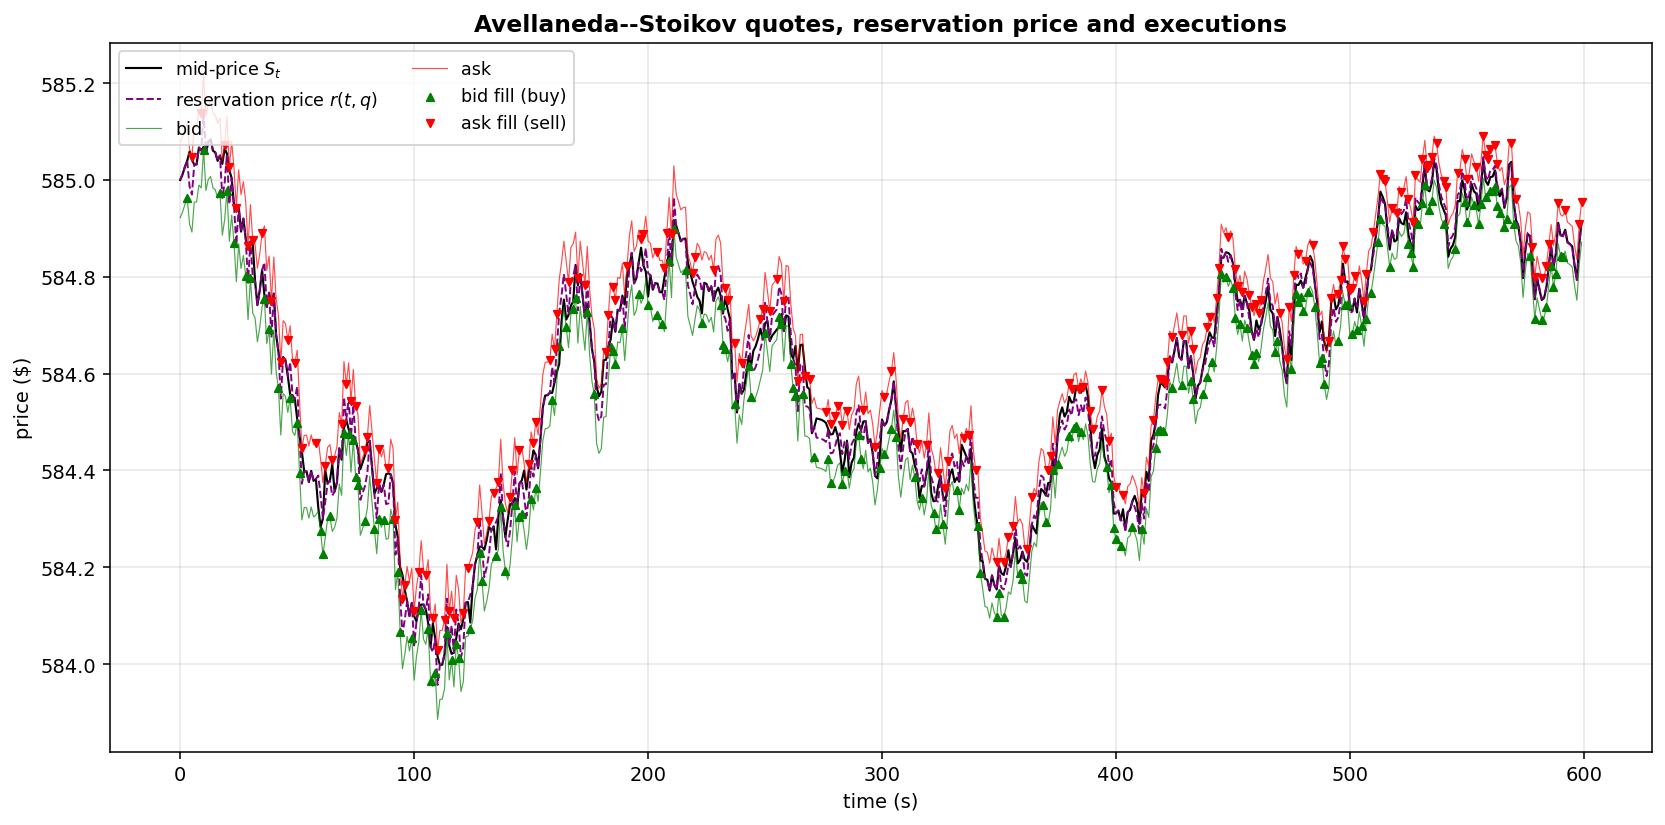

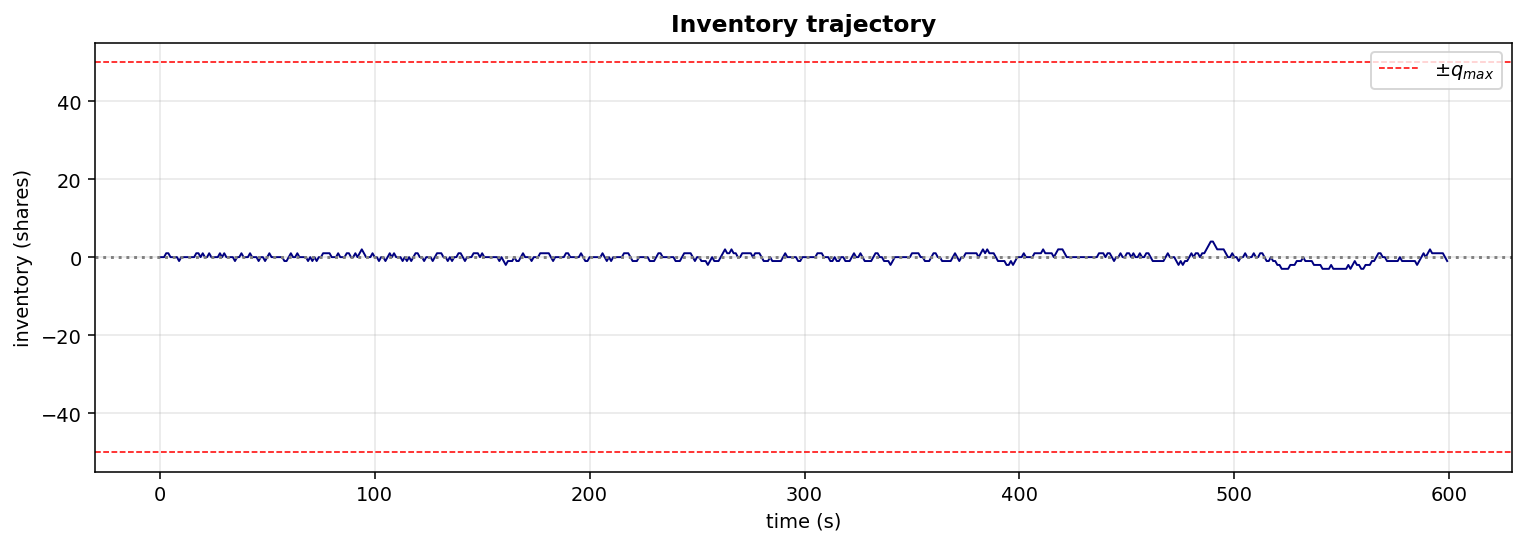

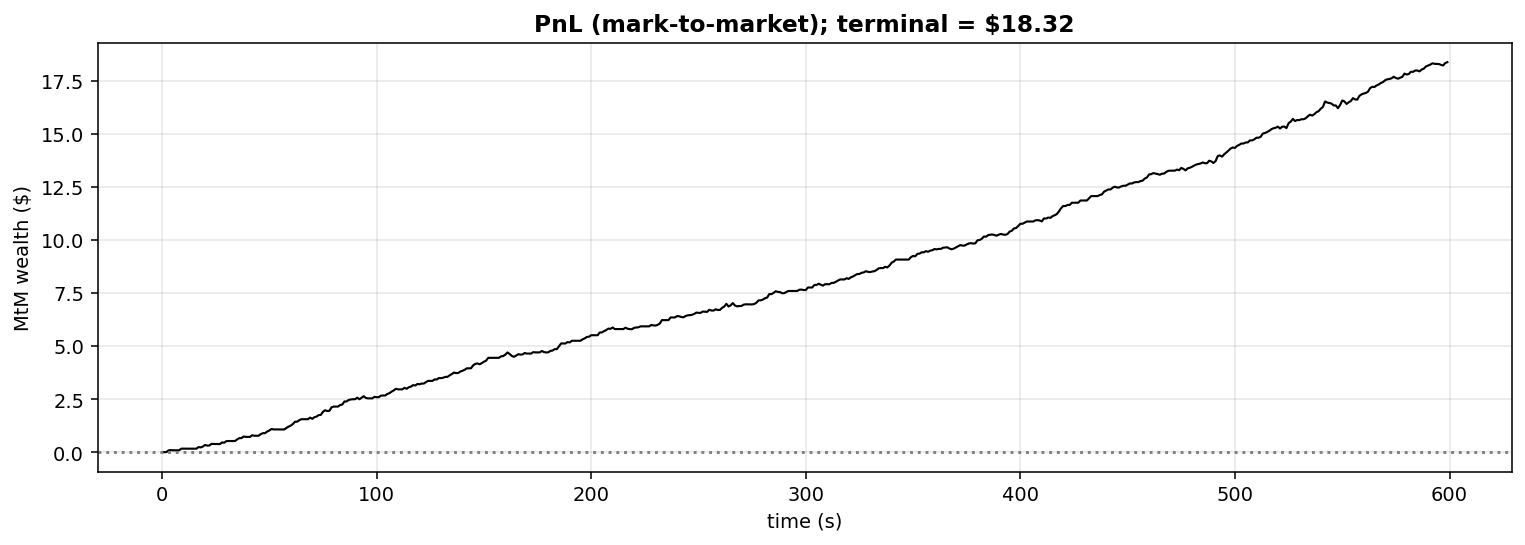

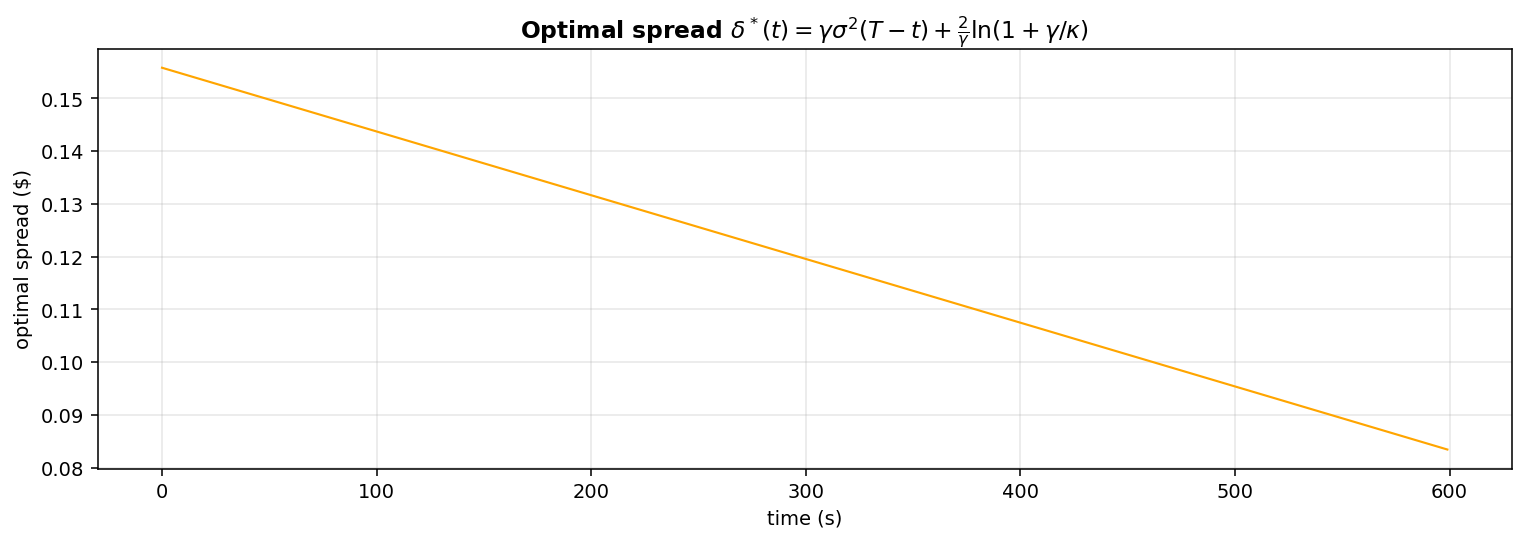

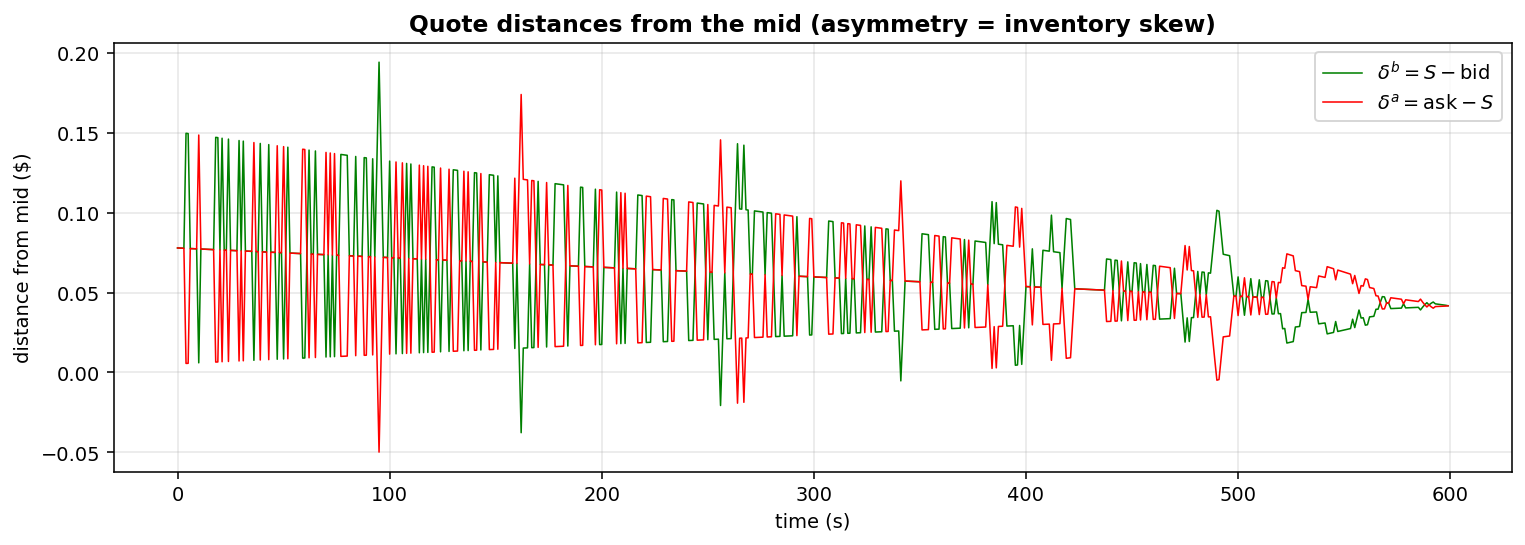

In [10]:
for f in ["episode_quotes_and_price.png","episode_inventory.png","episode_pnl.png",
          "episode_spread.png","episode_quote_distances.png"]:
    display(Image(filename=f"{PLOTS}/{f}"))

## 7. Sensitivity to risk aversion $\gamma$

We sweep $\gamma\in\{0.01,0.05,0.1,0.2,0.5\}$ over many Monte-Carlo price paths and measure the
effect on inventory, PnL, average spread and drawdown. (Full results computed by
`analysis/sensitivity.py` and loaded here.)

In [11]:
sweep = pd.read_parquet(f"{RESULTS}/as_gamma_sweep.parquet")
g = sweep.groupby("gamma")
summary = pd.DataFrame({"PnL_mean": g.terminal_pnl.mean(), "PnL_std": g.terminal_pnl.std(),
                        "inv_var": g.inv_var.mean(), "avg_spread": g.avg_spread.mean(),
                        "max_drawdown": g.max_drawdown.mean()})
display(summary.round(3))
print("As gamma rises: inventory variance and drawdown FALL, spread RISES, mean PnL falls "
      "(risk-return trade-off).")

,PnL_mean,PnL_std,inv_var,avg_spread,max_drawdown
gamma,,,,,
0.01,20.444,2.293,6.552,0.087,1.147
0.05,19.334,1.418,1.838,0.102,0.494
0.10,17.692,1.191,1.076,0.120,0.349
0.20,14.303,1.052,0.613,0.156,0.249
0.50,7.498,0.806,0.271,0.264,0.193


As gamma rises: inventory variance and drawdown FALL, spread RISES, mean PnL falls (risk-return trade-off).


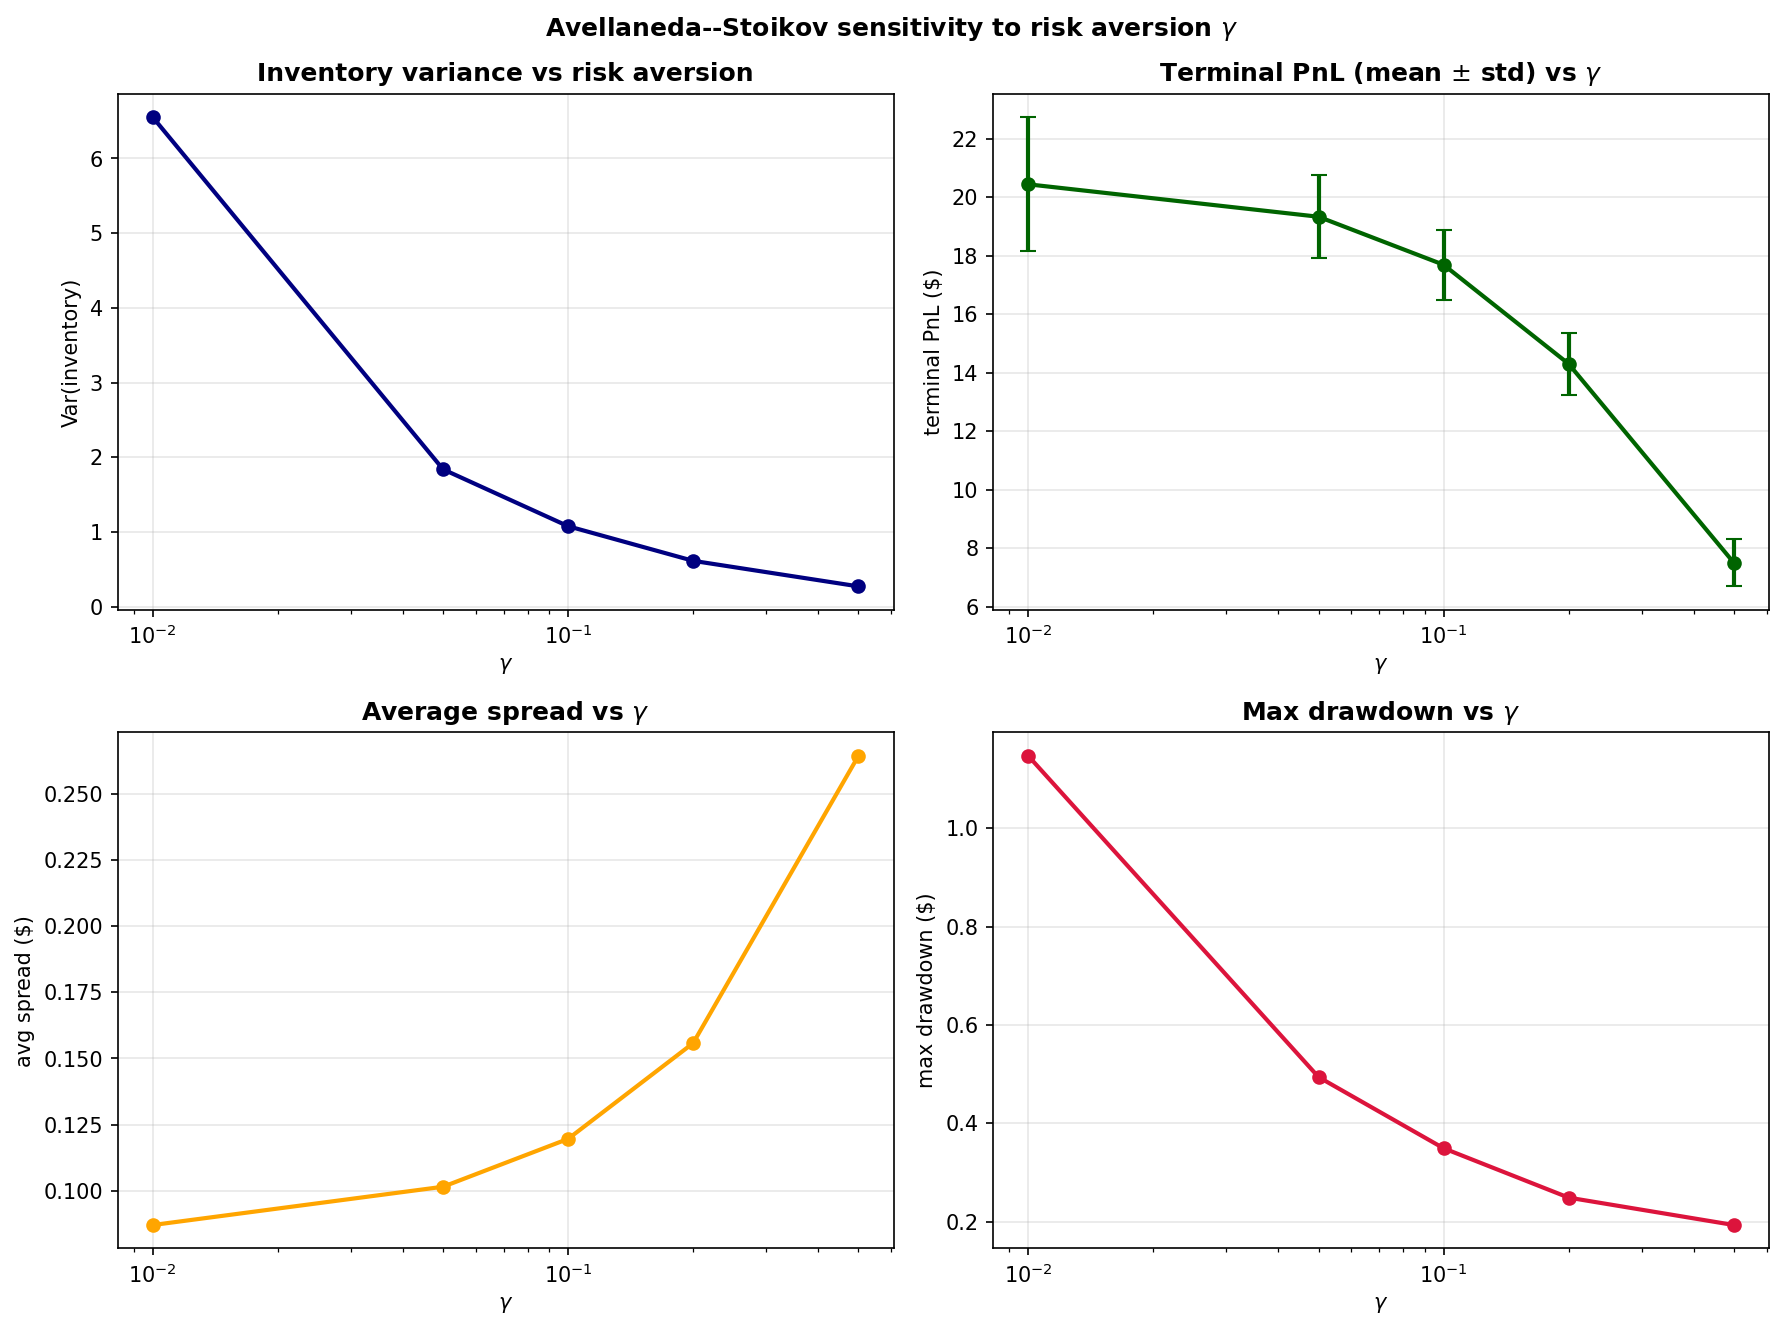

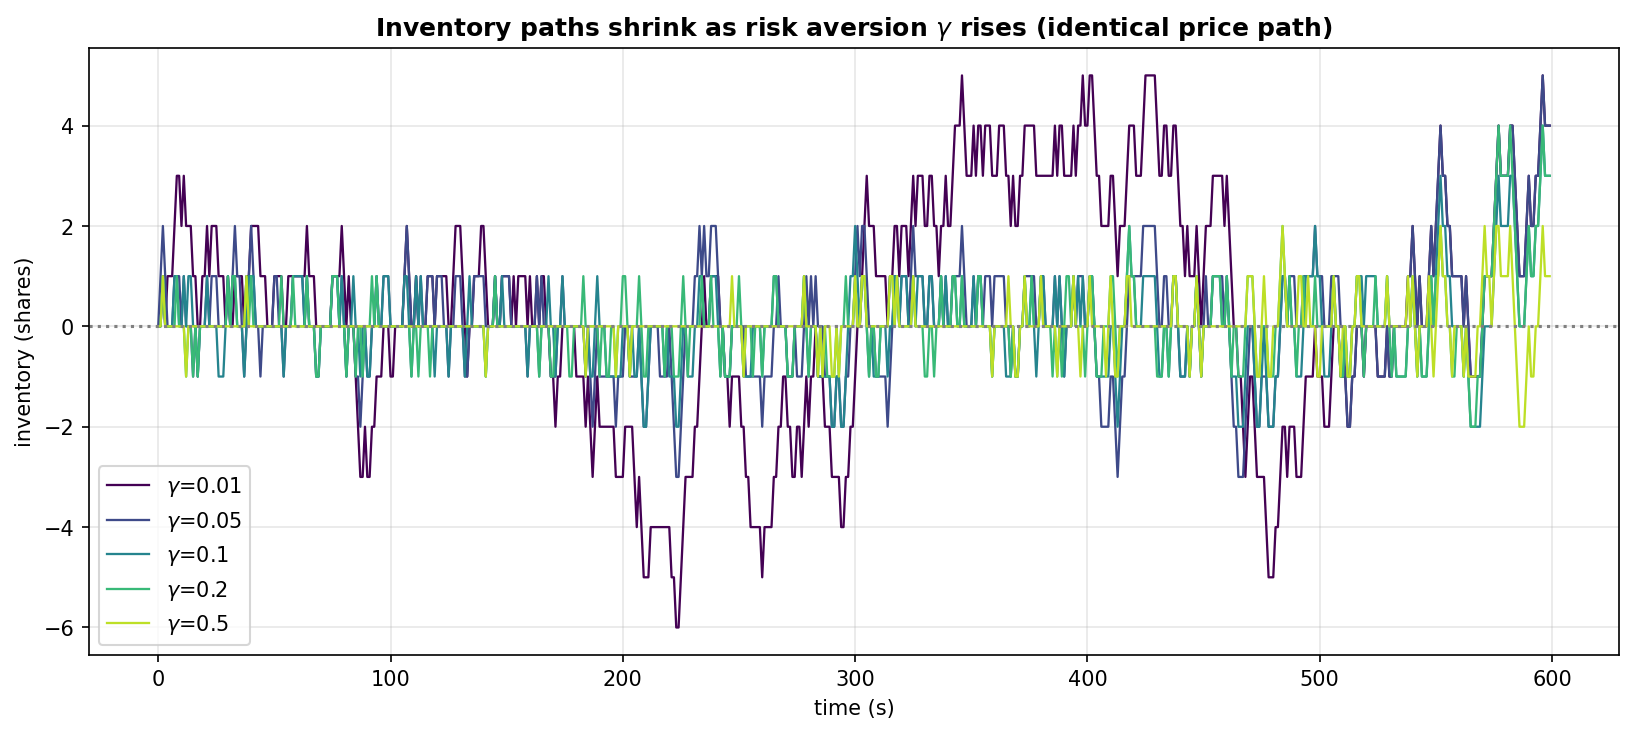

In [12]:
for f in ["sensitivity_gamma.png","sensitivity_inventory_paths.png"]:
    display(Image(filename=f"{PLOTS}/{f}"))

## 8. Numerical verification of the model's claims

Three predictions, each checked against numbers.

In [13]:
# Claim 1: reservation price is exactly linear in q, slope = -gamma sigma^2 (T-t)
qs = np.arange(-50, 51)
rs = np.array([reservation_price(585.0, q, 0.0, params) for q in qs])
slope, intercept = np.polyfit(qs, rs, 1)
theo = -params.gamma*sigma**2*(params.T-0.0)
print("CLAIM 1 — reservation linear in q:")
print(f"  fitted slope = {slope:.6e}   theoretical = {theo:.6e}   "
      f"max deviation from line = {np.max(np.abs(rs-(slope*qs+intercept))):.2e}  (machine precision)")

# Claim 2: spread increases with gamma
gs = [0.01,0.05,0.1,0.2,0.5]
sp = [optimal_spread(0.0, ASParameters(gamma=g,sigma=sigma,kappa=kappa,A=A,T=600.0)) for g in gs]
print("\nCLAIM 2 — spread increases with gamma:")
for g,s_ in zip(gs,sp): print(f"  gamma={g:<5} spread=${s_:.4f}")
print(f"  monotonically increasing: {all(np.diff(sp)>0)}")

# Claim 3: inventory variance decreases with gamma
print("\nCLAIM 3 — inventory variance decreases with gamma:")
for g,v in summary['inv_var'].items(): print(f"  gamma={g:<5} Var(inv)={v:.3f}")
print(f"  monotonically decreasing: {all(np.diff(summary['inv_var'].values)<0)}")

CLAIM 1 — reservation linear in q:
  fitted slope = -7.251658e-02   theoretical = -7.251658e-02   max deviation from line = 3.41e-13  (machine precision)

CLAIM 2 — spread increases with gamma:
  gamma=0.01  spread=$0.0907
  gamma=0.05  spread=$0.1196
  gamma=0.1   spread=$0.1558
  gamma=0.2   spread=$0.2282
  gamma=0.5   spread=$0.4452
  monotonically increasing: True

CLAIM 3 — inventory variance decreases with gamma:
  gamma=0.01  Var(inv)=6.552
  gamma=0.05  Var(inv)=1.838
  gamma=0.1   Var(inv)=1.076
  gamma=0.2   Var(inv)=0.613
  gamma=0.5   Var(inv)=0.271
  monotonically decreasing: True


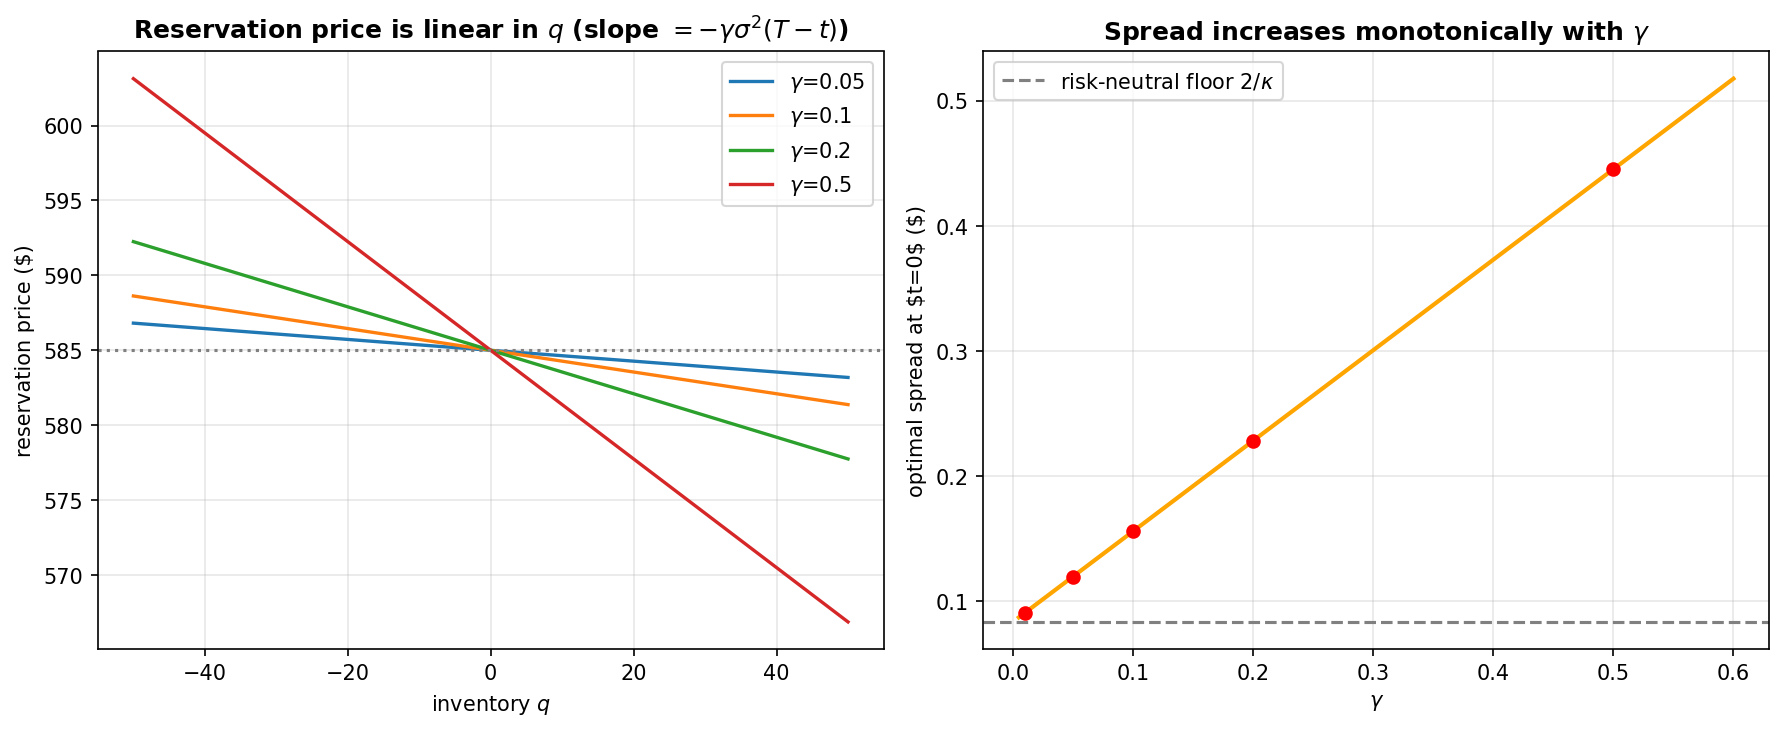

In [14]:
display(Image(filename=f"{PLOTS}/verification.png"))

## 9. Limitations — and why Hawkes comes next

The closed forms above are *only* available because arrivals are assumed **Poisson** — independent,
with a constant per-distance rate. But that is exactly the assumption Phases 1–3 **rejected** for
real AAPL trades:

| Phase-1/2/3 evidence | Implication for AS |
|---|---|
| CV $\approx2.6$, Ljung–Box & KS reject Poisson | arrival timing is mis-modelled |
| Self-excitation, branching ratio $\rho\approx0.47$ | fills cluster in bursts AS cannot see |
| Bursts often carry informed flow | constant intensity underprices adverse-selection risk |

A constant-intensity maker keeps quoting the same width through a trade cascade and gets run over.
The **Hawkes extension (next phase)** replaces $\lambda(\delta)=Ae^{-\kappa\delta}$ with a
self-exciting $\lambda(t,\delta)$ that jumps after each trade, letting the maker **widen exactly when
execution risk spikes**. The faithful classical model built here is the baseline that extension must
beat.

### Summary
We reproduced Avellaneda–Stoikov (2008) end-to-end from data-calibrated inputs, derived the
reservation price and optimal spread, simulated the strategy, ran a $\gamma$ sensitivity study and
numerically verified all three qualitative predictions. Full write-up:
`reports/avellaneda_stoikov_report.md`.

> **Out of scope (next phases):** Hawkes-driven intensities and reinforcement learning.